# Descargar librerías

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.pyplot as plt

# Leer archivo

In [2]:
df = pd.read_csv('../data/logs.csv')
df.head()

,_id,_ignored,_index,_score,@timestamp,@version,event_code_version,event_hash,@event_time_requested,headers_content_type,...,llm_total_tokens,llm_response_time_ms,llm_response_size_bytes,llm_status,llm_error_message,llm_cost_usd,llm_temperature,llm_top_p,llm_stream,llm_finish_reason
0,23bb795f-593c-4f5b-95f6-9ed2ee49d447,NaN,sap-logs-2026.04,0.7863,2026-04-17T22:12:18.000Z,1,1.8.7,bb746db61f0d38437ff6e0e4a3a425399f925aa0333352...,2026-04-17T22:12:17.748Z,application/json,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,a112d657-a776-4029-99fa-a9660dbae0de,NaN,sap-logs-2026.04,0.7308,2026-04-11T17:03:42.000Z,1,3.3.1,bcfb7885820cd48670812afd73f1537747eebf3ba54272...,2026-04-11T17:03:41.551Z,text/plain,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,e6c68fea-c4c2-4dd5-9335-f503f43731a9,NaN,sap-logs-2026.04,0.6168,2026-04-11T06:28:17.000Z,1,1.6.2,8f681cbb899fa6ef1832c56566c0ccfc0fe43bb936b2d9...,2026-04-11T06:28:16.705Z,application/x-www-form-urlencoded,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,75225251-b3d5-4a76-97dc-9fcc5f29eeba,NaN,llm-logs-2026.04,0.9530,2026-04-12T12:57:39.000Z,1,1.8.9,ad44a6f8dc6cbad0036218cbc65ae386ab53c846bfe686...,2026-04-12T12:57:38.340Z,application/xml,...,2680.0,31911.58,NaN,timeout,Request timed out after 30 s.,0.0536,0.26,0.92,False,timeout
4,4ad51ca3-c950-4bfb-9914-d4d9e1f104c6,NaN,sap-logs-2026.04,0.5392,2026-04-12T06:35:20.000Z,1,3.4.0,ccb84bedaa608eaf29f7b5347708d19fa39bfd29504b11...,2026-04-12T06:35:19.946Z,application/xml,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


# Primer análisis

In [4]:
df.describe()

,_ignored,_score,@version,sap_llm_response_size,sap_llm_response_time,http_status_code,llm_prompt_tokens,llm_completion_tokens,llm_total_tokens,llm_response_time_ms,llm_response_size_bytes,llm_cost_usd,llm_temperature,llm_top_p
count,0.0,1.931412e+06,1931412.0,540459.000000,772565.000000,1.158847e+06,772565.000000,772565.000000,772565.000000,772565.000000,540459.000000,772565.000000,772565.000000,772565.000000
mean,NaN,7.499678e-01,1.0,16503.841842,8772.606362,2.627992e+02,1023.053338,764.707612,1787.760950,8772.606362,16503.841842,0.012463,0.749752,0.749939
std,NaN,1.444482e-01,0.0,9395.425989,8726.652008,1.025674e+02,563.181345,424.944257,705.779483,8726.652008,9395.425989,0.018865,0.432674,0.144389
min,NaN,5.000000e-01,1.0,256.000000,200.000000,2.000000e+02,50.000000,30.000000,82.000000,200.000000,256.000000,0.000007,0.000000,0.500000
25%,NaN,6.249000e-01,1.0,8354.000000,2296.770000,2.000000e+02,535.000000,396.000000,1274.000000,2296.770000,8354.000000,0.000752,0.380000,0.620000
50%,NaN,7.500000e-01,1.0,16478.000000,6517.320000,2.000000e+02,1023.000000,764.000000,1788.000000,6517.320000,16478.000000,0.005424,0.750000,0.750000
75%,NaN,8.751000e-01,1.0,24656.000000,11816.970000,3.020000e+02,1510.000000,1133.000000,2301.000000,11816.970000,24656.000000,0.014664,1.120000,0.870000
max,NaN,1.000000e+00,1.0,32768.000000,34999.990000,5.040000e+02,2000.000000,1500.000000,3496.000000,34999.990000,32768.000000,0.139720,1.500000,1.000000


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1931412 entries, 0 to 1931411
Data columns (total 44 columns):
 #   Column                       Dtype  
---  ------                       -----  
 0   _id                          str    
 1   _ignored                     float64
 2   _index                       str    
 3   _score                       float64
 4   @timestamp                   str    
 5   @version                     int64  
 6   event_code_version           str    
 7   event_hash                   str    
 8   @event_time_requested        str    
 9   headers_content_type         str    
 10  headers_http_host            str    
 11  headers_http_request_method  str    
 12  heathers_request_path        str    
 13  sap_function_application     str    
 14  sap_source_type              str    
 15  sap_function_log_type        str    
 16  sap_function_message         str    
 17  sap_app_env                  str    
 18  sap_llm_response_size        float64
 19  sap_llm_res

# Separar datasets

In [7]:
df['_index'].nunique()

2

In [13]:
df_llm = df[df['_index'].str.startswith('llm-logs', na=False)]
df_system = df[df['_index'].str.startswith('sap-logs', na=False)]

# Exploración system

In [16]:
df_system['sap_function_log_type'].unique()

<StringArray>
['INFO', 'PERF', 'WARNING', 'AUDIT', 'DEBUG', 'ERROR', 'SECURITY']
Length: 7, dtype: str

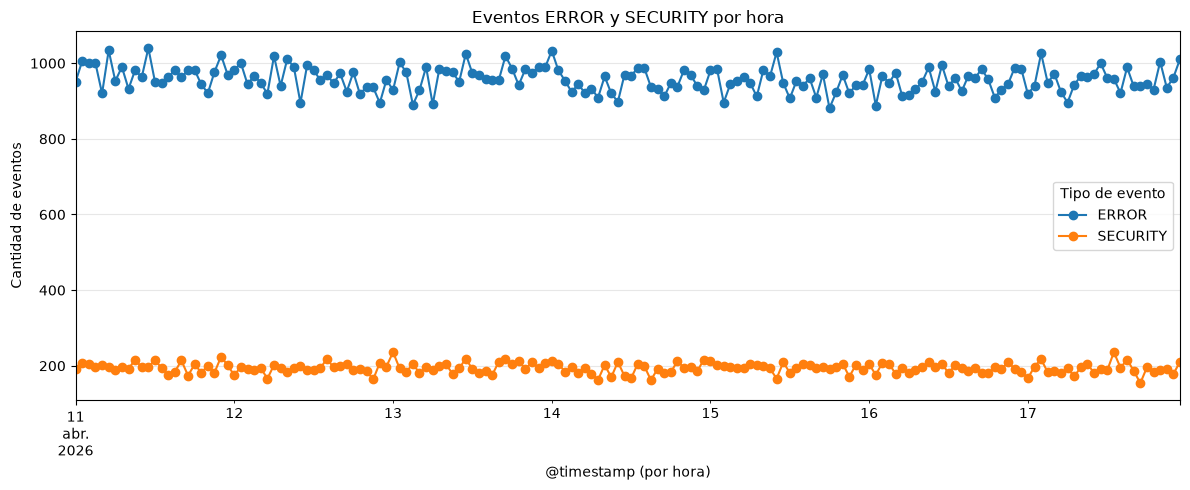

In [21]:
df_system_error_security = df_system[
    df_system["sap_function_log_type"].isin(["ERROR", "SECURITY"])
].copy()
df_system_error_security["@timestamp"] = pd.to_datetime(
    df_system_error_security["@timestamp"], utc=True
)

hourly_counts = (
    df_system_error_security.groupby(
        [pd.Grouper(key="@timestamp", freq="h"), "sap_function_log_type"]
    )
    .size()
    .unstack(fill_value=0)
    .reindex(columns=["ERROR", "SECURITY"], fill_value=0)
)
if not hourly_counts.empty:
    hourly_counts = hourly_counts.reindex(
        pd.date_range(
            hourly_counts.index.min(), hourly_counts.index.max(), freq="h"
        ),
        fill_value=0,
    )

fig, ax = plt.subplots(figsize=(12, 5))
hourly_counts.plot(ax=ax, marker="o")
ax.set_xlabel("@timestamp (por hora)")
ax.set_ylabel("Cantidad de eventos")
ax.set_title("Eventos ERROR y SECURITY por hora")
ax.legend(title="Tipo de evento")
ax.grid(True, axis="y", alpha=0.3)
fig.tight_layout()
plt.show()

# Exploración Llm

In [23]:
df_llm['sap_function_log_type'].unique()

<StringArray>
['LLM_TIMEOUT', 'LLM_REQUEST', 'LLM_ERROR']
Length: 3, dtype: str

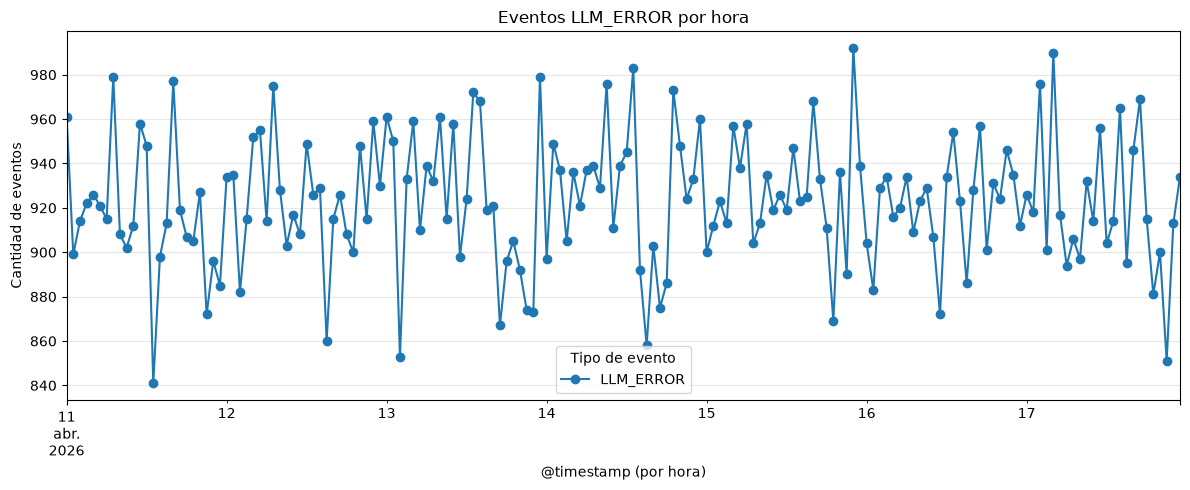

In [25]:
df_llm_error = df_llm[
    df_llm["sap_function_log_type"].isin(["LLM_ERROR"])
].copy()
df_llm_error["@timestamp"] = pd.to_datetime(
    df_llm_error["@timestamp"], utc=True
)

hourly_counts = (
    df_llm_error.groupby(
        [pd.Grouper(key="@timestamp", freq="h"), "sap_function_log_type"]
    )
    .size()
    .unstack(fill_value=0)
    .reindex(columns=["LLM_ERROR"], fill_value=0)
)
if not hourly_counts.empty:
    hourly_counts = hourly_counts.reindex(
        pd.date_range(
            hourly_counts.index.min(), hourly_counts.index.max(), freq="h"
        ),
        fill_value=0,
    )

fig, ax = plt.subplots(figsize=(12, 5))
hourly_counts.plot(ax=ax, marker="o")
ax.set_xlabel("@timestamp (por hora)")
ax.set_ylabel("Cantidad de eventos")
ax.set_title("Eventos LLM_ERROR por hora")
ax.legend(title="Tipo de evento")
ax.grid(True, axis="y", alpha=0.3)
fig.tight_layout()
plt.show()

In [26]:
df_llm[df_llm["sap_function_log_type"] == "LLM_ERROR"].head(10)

,_id,_ignored,_index,_score,@timestamp,@version,event_code_version,event_hash,@event_time_requested,headers_content_type,...,llm_total_tokens,llm_response_time_ms,llm_response_size_bytes,llm_status,llm_error_message,llm_cost_usd,llm_temperature,llm_top_p,llm_stream,llm_finish_reason
66,1ef4bbc8-e493-45bf-b5f4-9e82476462ee,NaN,llm-logs-2026.04,0.8003,2026-04-12T00:19:15.000Z,1,3.2.8,61a46ee8595e2f160b92c002798e1b28d21d354f878345...,2026-04-12T00:19:14.660Z,application/xml,...,2463.0,2309.87,NaN,error,Adversarial prompt pattern detected.,0.007389,0.93,0.73,True,length
95,e3049d41-3f81-4c91-affc-cf01261e126d,NaN,llm-logs-2026.04,0.6603,2026-04-17T15:19:16.000Z,1,3.0.5,a6171e735081fba24e4d6b268e5ec07faeebd4c0d77e6b...,2026-04-17T15:19:14.598Z,application/json,...,1513.0,766.81,NaN,error,Service temporarily unavailable.,0.006052,1.03,0.62,True,content_filter
104,2b365cac-612c-4dbc-9686-c0896884e7cf,NaN,llm-logs-2026.04,0.7483,2026-04-15T05:31:24.000Z,1,1.8.7,4b5fb6e88401aaa45ed40e733d79a0864b0e7278440ce7...,2026-04-15T05:31:23.829Z,application/xml,...,2248.0,2121.85,NaN,error,Model checkpoint no longer supported.,0.022480,0.18,0.69,True,content_filter
124,b0b8e398-1a6e-4b4b-97c1-776ce4a768ab,NaN,llm-logs-2026.04,0.8815,2026-04-15T16:18:01.000Z,1,1.3.8,f91a39ee7c17b9458bd9ba6d9079f2f6738d5c3620fe58...,2026-04-15T16:17:59.047Z,application/xml,...,3130.0,2945.37,NaN,error,Vector embedding size does not match index.,0.046950,1.26,0.67,False,length
140,74fe2124-9fd9-451b-9b45-879352b19a60,NaN,llm-logs-2026.04,0.6646,2026-04-12T17:17:40.000Z,1,2.2.7,a3846bf5efb702ef6adbede9fe43f5dd64f227b2ff5eff...,2026-04-12T17:17:38.551Z,text/plain,...,1897.0,1780.44,NaN,error,Token log probabilities not supported here.,0.001518,1.08,0.57,True,content_filter
156,6ae163b5-7f3d-4a83-a11e-b9ca9696ea3b,NaN,llm-logs-2026.04,0.6646,2026-04-17T20:38:38.000Z,1,1.7.5,1535d76a007f70eec33abe7eefbf169d0f578b3b6b9321...,2026-04-17T20:38:36.767Z,multipart/form-data,...,779.0,436.03,NaN,error,SSE stream terminated before completion.,0.000234,0.50,0.74,False,content_filter
159,1432fb60-caf0-4761-9db5-ceefad5e9861,NaN,llm-logs-2026.04,0.9238,2026-04-11T07:27:08.000Z,1,2.4.9,ff66366f8307d2e93112e6c42f203666af68e991f15360...,2026-04-11T07:27:06.110Z,application/x-www-form-urlencoded,...,2060.0,1804.64,NaN,error,Request with this ID was already processed.,0.000618,1.10,0.51,True,content_filter
162,01d6afdc-e544-4b8e-b024-0bb3be35df93,NaN,llm-logs-2026.04,0.8690,2026-04-15T22:57:01.000Z,1,1.1.2,f3deab7901f2169bd79a9ed8925747e45ce07cdbd218bd...,2026-04-15T22:56:59.967Z,application/x-www-form-urlencoded,...,2878.0,644.28,NaN,error,Insufficient quota for this request.,0.002302,0.14,0.79,False,length
173,60c40ee5-4ab6-4e9f-a7bf-3daa01a8b8e2,NaN,llm-logs-2026.04,0.8936,2026-04-12T00:25:28.000Z,1,2.6.2,0b100428e91cb28a32f20ad8c7705b8fb45023ee2727ac...,2026-04-12T00:25:27.626Z,application/x-www-form-urlencoded,...,2603.0,2946.52,NaN,error,System prompt exceeds maximum length.,0.020824,0.54,0.93,True,content_filter
176,d87fd458-0bd4-42be-8a03-9b41efe5ad96,NaN,llm-logs-2026.04,0.5139,2026-04-15T02:05:53.000Z,1,2.0.3,8b7630779c2c18a9e389e6d63ff52f307e1cdbac7dbe3b...,2026-04-15T02:05:51.072Z,application/x-www-form-urlencoded,...,2361.0,1497.14,NaN,error,Function calling payload malformed.,0.035415,0.10,0.99,True,length


In [27]:
df_llm_error[["message", "model", "app"]] = df_llm_error[
    "sap_function_message"
].str.extract(
    r"^(?P<message>.*?) \(model=(?P<model>[^,]+), app=(?P<app>[^)]+)\)$"
)

df_llm_error[["sap_function_message", "message", "model", "app"]].head()

,sap_function_message,message,model,app
66,LLM ERROR: Adversarial prompt pattern detected...,LLM ERROR: Adversarial prompt pattern detected.,claude-3-7-sonnet,sap-btp-cf
95,LLM ERROR: Service temporarily unavailable. (m...,LLM ERROR: Service temporarily unavailable.,claude-sonnet-4.6,sap-concur
104,LLM ERROR: Model checkpoint no longer supporte...,LLM ERROR: Model checkpoint no longer supported.,gpt-4-turbo,sap-intelligent-rpa
124,LLM ERROR: Vector embedding size does not matc...,LLM ERROR: Vector embedding size does not matc...,claude-3-opus,sap-analytics-cloud
140,LLM ERROR: Token log probabilities not support...,LLM ERROR: Token log probabilities not support...,claude-3-5-haiku,sap-s4hana-finance


In [29]:
df_llm_error['message'].value_counts().head(10)

message
LLM ERROR: This capability is not available on trial plans.     792
LLM ERROR: Session token limit has been reached.                782
LLM ERROR: Token log probabilities not supported here.          776
LLM ERROR: Rate limit exceeded.                                 773
LLM ERROR: GPU memory allocation failed.                        770
LLM ERROR: Fine-tuned model not found.                          769
LLM ERROR: Submitted media format is not supported.             768
LLM ERROR: User message missing from request.                   766
LLM ERROR: Load balancer could not route request.               765
LLM ERROR: Provider API returned an unrecognized error code.    764
Name: count, dtype: int64

In [30]:
df_llm_error['model'].unique()

<StringArray>
[    'claude-3-7-sonnet',     'claude-sonnet-4.6',           'gpt-4-turbo',
         'claude-3-opus',      'claude-3-5-haiku',       'mistral-small-4',
        'gemini-3.1-pro',                    'o1',       'claude-3-sonnet',
   'mistral-7b-instruct',   'gemini-1.5-flash-8b',          'grok-4.20-b2',
        'claude-3-haiku',     'claude-3-5-sonnet',               'gpt-5.4',
       'claude-opus-4.6',               'o3-mini',                 'gpt-4',
        'gemini-1.5-pro', 'gemini-3.1-flash-lite',      'gemini-2.0-flash',
         'gpt-3.5-turbo',           'gpt-5.4-pro',        'gemini-2.0-pro',
      'nemotron-3-super',      'gemini-1.5-flash',                'gpt-4o',
               'o1-mini',           'gpt-4o-mini']
Length: 29, dtype: str

In [33]:
df_llm_error['model'].value_counts().head(29)

model
gpt-5.4                  5483
claude-3-sonnet          5472
grok-4.20-b2             5464
gemini-2.0-pro           5442
claude-opus-4.6          5429
claude-3-7-sonnet        5407
claude-3-5-haiku         5405
o3-mini                  5397
claude-3-opus            5396
gemini-1.5-pro           5395
gpt-5.4-pro              5390
gpt-4-turbo              5388
nemotron-3-super         5387
gemini-3.1-pro           5384
claude-3-haiku           5379
gpt-4o-mini              5357
gpt-3.5-turbo            5348
o1                       5310
claude-sonnet-4.6        5309
mistral-small-4          5302
gpt-4                    5282
gemini-1.5-flash         5276
gemini-1.5-flash-8b      5275
gemini-3.1-flash-lite    5269
claude-3-5-sonnet        5255
gemini-2.0-flash         5244
gpt-4o                   5233
mistral-7b-instruct      5200
o1-mini                  5180
Name: count, dtype: int64